## Step 1: Load the 16 Rugby World Cup 2027 countries
The country columns are split across three Census files (G09F, G09G, G09H). I load only the columns I need from each file and join them on the SA2 code. One row = one SA2 area.

In [91]:
import pandas as pd

data_path = '/kaggle/input/datasets/somahattori/victoria-census-2021-country-of-birth-g09-sa2/'

cols_f = ['P_Canada_Tot', 'P_Chile_Tot', 'P_England_Tot', 'P_Fiji_Tot', 'P_France_Tot']
cols_g = ['P_Hong_Kong_SAR_Ch_Tot', 'P_Ireland_Tot', 'P_Italy_Tot', 'P_Japan_Tot', 'P_New_Zealand_Tot']
cols_h = ['P_Samoa_Tot', 'P_Scotland_Tot', 'P_South_Africa_Tot', 'P_USA_Tot', 'P_Wales_Tot', 'P_Zimbabwe_Tot']

g09f = pd.read_csv(data_path + '2021Census_G09F_VIC_SA2.csv', usecols=['SA2_CODE_2021'] + cols_f)
g09g = pd.read_csv(data_path + '2021Census_G09G_VIC_SA2.csv', usecols=['SA2_CODE_2021'] + cols_g)
g09h = pd.read_csv(data_path + '2021Census_G09H_VIC_SA2.csv', usecols=['SA2_CODE_2021'] + cols_h + ['P_Tot_Tot'])

df = g09f.merge(g09g, on='SA2_CODE_2021').merge(g09h, on='SA2_CODE_2021')

country_cols = cols_f + cols_g + cols_h
df['world_cup_born'] = df[country_cols].sum(axis=1)

print(df.shape)
df.head()

(524, 19)


,SA2_CODE_2021,P_Canada_Tot,P_Chile_Tot,P_England_Tot,P_Fiji_Tot,P_France_Tot,P_Hong_Kong_SAR_Ch_Tot,P_Ireland_Tot,P_Italy_Tot,P_Japan_Tot,P_New_Zealand_Tot,P_Samoa_Tot,P_Scotland_Tot,P_South_Africa_Tot,P_USA_Tot,P_Wales_Tot,P_Zimbabwe_Tot,P_Tot_Tot,world_cup_born
0,201011001,17,15,333,20,7,9,25,13,15,151,0,47,74,27,12,40,16835,805
1,201011002,24,3,282,3,11,18,38,15,21,130,3,47,26,67,13,3,12131,704
2,201011005,6,0,268,5,0,5,11,12,9,64,0,32,14,19,5,3,7261,453
3,201011006,12,4,161,4,3,3,7,12,9,100,3,25,8,19,6,11,10661,387
4,201011007,4,3,102,0,5,0,8,4,0,30,0,20,6,12,0,0,4230,194


**What one row means:** one row is one SA2 area. SA2 (Statistical Area Level 2) is the ABS's suburb-sized unit, usually with about 3,000 to 25,000 residents.

**Columns:**
- `SA2_CODE_2021`: the area's ID
- `P_<Country>_Tot`: number of residents born in that country (2021 Census)
- `P_Tot_Tot`: total residents in the area
- `world_cup_born`: the sum of the 16 country columns

## Step 2: Keep Melbourne and Geelong
The first three digits of an SA2 code are its SA4 region. I keep Greater Melbourne (206–214) and Geelong (203), the two largest urban areas in Victoria, and add a `city` column.

In [92]:
geo_path = '/kaggle/input/datasets/somahattori/abs-2021-geography-names/2021Census_geog_desc_1st_2nd_3rd_release.xlsx'
geo = pd.read_excel(geo_path, sheet_name='2021_ASGS_MAIN_Structures')
sa4_names = geo[geo['ASGS_Structure'] == 'SA4'][['Census_Code_2021', 'Census_Name_2021']]
sa4_names['Census_Code_2021'] = sa4_names['Census_Code_2021'].astype(int)

pop = df.assign(sa4=df['SA2_CODE_2021'].astype(str).str[:3].astype(int))
sa4_pop = pop.groupby('sa4')['P_Tot_Tot'].sum().reset_index()
sa4_pop = sa4_pop.merge(sa4_names, left_on='sa4', right_on='Census_Code_2021')
sa4_pop.sort_values('P_Tot_Tot', ascending=False)[['sa4', 'Census_Name_2021', 'P_Tot_Tot']]

,sa4,Census_Name_2021,P_Tot_Tot
11,212,Melbourne - South East,860044
12,213,Melbourne - West,853049
5,206,Melbourne - Inner,617037
8,209,Melbourne - North East,540648
10,211,Melbourne - Outer East,518300
9,210,Melbourne - North West,424303
7,208,Melbourne - Inner South,422648
6,207,Melbourne - Inner East,373471
2,203,Geelong,327884
13,214,Mornington Peninsula,308217


### Why Melbourne and Geelong?
Population by SA4 region (2021 Census). Outside the nine Greater Melbourne regions (206–214), Geelong is the largest at about 328,000, almost twice the size of Ballarat. Latrobe–Gippsland is similar in size, but it is a wide area of several smaller towns, not one city, and it is about two hours from Marvel Stadium.

In [93]:
df['sa4'] = df['SA2_CODE_2021'].astype(str).str[:3].astype(int)

city_map = {203: 'Geelong'}
for code in range(206, 215):
    city_map[code] = 'Melbourne'

df = df[df['sa4'].isin(city_map.keys())].copy()
df['city'] = df['sa4'].map(city_map)

print(df.shape)
print(df['P_Tot_Tot'].sum())
df['city'].value_counts()

(384, 21)
5245601


city
Melbourne    361
Geelong       23
Name: count, dtype: int64

**Result:** 384 areas remain: 361 in Greater Melbourne and 23 in Geelong. Together they have 5,245,601 residents, which matches the SA4 population table above.

## Step 3: Remove very small areas, add shares and area names
Areas with fewer than 1,000 residents (e.g. industrial zones, airports, parks) are removed, because a handful of people can make their share look extreme. `world_cup_share` is the percentage of residents in each area who were born in one of the 23 countries. `sa2_names` is a lookup table of SA2 codes and names from the ABS geography file; I join it to add each area's name as the `sa2_name` column.

In [94]:
df_cleaned = df[df['P_Tot_Tot'] >= 1000].copy()
df_cleaned['world_cup_share'] = (df_cleaned['world_cup_born'] / 
                                 df_cleaned['P_Tot_Tot'] * 100).round(1)

sa2_names = geo[geo['ASGS_Structure'] == 'SA2'][['Census_Code_2021', 'Census_Name_2021']].copy()
sa2_names['Census_Code_2021'] = sa2_names['Census_Code_2021'].astype(int)
sa2_names = sa2_names.rename(columns={'Census_Code_2021': 'SA2_CODE_2021', 'Census_Name_2021': 'sa2_name'})

df_merged = df_cleaned.merge(sa2_names, on='SA2_CODE_2021', how='left')

print(df_merged.shape)
print(df_merged['sa2_name'].isna().sum())
print(df_merged['world_cup_born'].sum())

(377, 23)
0
462321


**Result:**
- `(377, 23)`: 7 areas with fewer than 1,000 residents were removed, leaving 377. Two columns were added: `world_cup_share` and `sa2_name`.
- `0`: every area was matched to a name.
- `462321`: 462,321 residents of these 377 areas were born in one of the 23 Rugby World Cup 2027 countries.

### Step 3b: Add the seven countries from TableBuilder
Seven teams (Argentina, Georgia, Portugal, Romania, Spain, Tonga and Uruguay) have no column in table G09, so I downloaded their country of birth counts by SA2 from ABS Census TableBuilder. The file has SA2 names but no SA2 codes, so I match it to my areas by name.

In [95]:
bplp_path = '/kaggle/input/datasets/somahattori/abs-2021-bplp-7countries/vic_sa2_bplp_7countries.xlsx'
bplp_raw = pd.read_excel(bplp_path, header=None)

bplp = bplp_raw.iloc[10:2482, 1:9].copy()
bplp.columns = ['sa2_name'] + bplp_raw.iloc[8, 2:9].tolist()
new_cols = bplp.columns[1:].tolist()
bplp[new_cols] = bplp[new_cols].astype(int)
df_merged['sa2_name'] = df_merged['sa2_name'].str.strip()
bplp['sa2_name'] = bplp['sa2_name'].str.strip()

matched = df_merged['sa2_name'].isin(bplp['sa2_name'])
print(bplp.shape)
print('Duplicate names:', bplp['sa2_name'].duplicated().sum())
print(matched.sum(), 'of', len(df_merged), 'areas matched')
df_merged.loc[~matched, 'sa2_name']

(2472, 8)
Duplicate names: 0
377 of 377 areas matched


Series([], Name: sa2_name, dtype: object)

**Result:** The TableBuilder file has 2,472 areas for all of Australia, with no repeated names. All 377 of my areas matched by name, after removing a trailing space from one name in the G09 data (Highett (East) - Cheltenham).

In [96]:
df_merged = df_merged.drop(columns=new_cols, errors='ignore')
df_merged = df_merged.merge(bplp, on='sa2_name', how='left')

country_cols_all = country_cols + new_cols
df_merged['world_cup_born'] = df_merged[country_cols_all].sum(axis=1)
df_merged['world_cup_share'] = (df_merged['world_cup_born'] / 
                                df_merged['P_Tot_Tot'] * 100).round(1)
print(df_merged.shape)
print(df_merged[new_cols].sum())
print('World Cup-born total:', df_merged['world_cup_born'].sum())

(377, 30)
Romania      5278
Spain        3500
Uruguay      1456
Argentina    4320
Tonga        1406
Portugal     2924
Georgia       183
dtype: int64
World Cup-born total: 481388


**Result:** The seven countries add 19,067 people, so the World Cup-born total rises from 462,321 to 481,388 across the 377 areas. Romania (5,278), Argentina (4,320) and Spain (3,500) add the most. Georgia adds only 183.


## Step 4: Top 10 areas
I rank areas in two ways. **By number** shows where the most potential ticket buyers live. **By share** shows where they make up the largest part of the local population, which is useful for targeting local advertising.

In [97]:
show = ['sa2_name', 'city', 'P_Tot_Tot', 'world_cup_born', 'world_cup_share']
df_merged.sort_values('world_cup_born', ascending=False)[show].head(10)

,sa2_name,city,P_Tot_Tot,world_cup_born,world_cup_share
99,Brighton (Vic.),Melbourne,22758,3071,13.5
371,Mount Martha,Melbourne,19846,2962,14.9
104,Bentleigh - McKinnon,Melbourne,24896,2917,11.7
61,Prahran - Windsor,Melbourne,19119,2915,15.2
370,Mount Eliza,Melbourne,18734,2903,15.5
106,Caulfield - North,Melbourne,22362,2895,12.9
344,Point Cook - East,Melbourne,19274,2845,14.8
107,Caulfield - South,Melbourne,18075,2818,15.6
361,Frankston,Melbourne,23586,2769,11.7
122,Mordialloc - Parkdale,Melbourne,21199,2724,12.8


In [98]:
df_merged.sort_values('world_cup_share', ascending=False)[show].head(10)

,sa2_name,city,P_Tot_Tot,world_cup_born,world_cup_share
58,St Kilda - Central,Melbourne,11857,2221,18.7
59,St Kilda - West,Melbourne,13858,2402,17.3
138,Reservoir - North West,Melbourne,9801,1664,17.0
63,South Yarra - North,Melbourne,11192,1881,16.8
376,Mornington - West,Melbourne,10581,1699,16.1
56,Port Melbourne Industrial,Melbourne,1907,301,15.8
107,Caulfield - South,Melbourne,18075,2818,15.6
370,Mount Eliza,Melbourne,18734,2903,15.5
103,Sandringham - Black Rock,Melbourne,17358,2658,15.3
61,Prahran - Windsor,Melbourne,19119,2915,15.2


In [99]:
total_pop = df_merged['P_Tot_Tot'].sum()
total_wc = df_merged['world_cup_born'].sum()
overall_share = total_wc / total_pop * 100
top_share = df_merged['world_cup_share'].max()

print(total_pop)
print(total_wc)
print(round(overall_share, 1))
print(round(top_share, 1), round(top_share / overall_share, 2))

5245328
481388
9.2
18.7 2.04


**Result:** Across the 377 areas, 481,388 of 5,245,328 residents (9.2%) were born in one of the 23 countries. The highest share, in St Kilda – Central (18.7%), is about twice this average.
### What the two tables show
- **One clear band.** Almost all top areas run along the east side of Port Phillip Bay: the inner south (St Kilda, Prahran, South Yarra), the bayside suburbs (Brighton, Bentleigh, Caulfield, Sandringham, Mordialloc) and the Mornington Peninsula (Frankston, Mornington, Mount Eliza, Mount Martha). The exceptions are Point Cook – East and Reservoir – North West.

- **No single standout area.** By number, the top 10 range only from 2,724 to 3,071 people, so demand is spread across the band rather than concentrated in one suburb.

- **Number and share point to different areas.** Smaller inner-south areas lead by share, larger suburbs lead by number. Only Mount Eliza, Caulfield – South and Prahran – Windsor appear in both lists.

- **No Geelong area** appears in either top 10.

- **Caution:** Port Melbourne Industrial has only 1,907 residents, so its high share is not treated as a finding.

### Main country in the top 10 areas
The same top 10 areas by number as above, with a new `top_country` column showing which of the 23 countries has the most residents in each area.

In [100]:
df_merged['top_country'] = df_merged[country_cols_all].idxmax(axis=1).str.replace('P_', '').str.replace('_Tot', '')
df_merged['top_country_pct'] = (df_merged[country_cols_all].max(axis=1) / df_merged['world_cup_born'] * 100).round(1)

df_merged.sort_values('world_cup_born', ascending=False)[show + ['top_country', 'top_country_pct']].head(10)

,sa2_name,city,P_Tot_Tot,world_cup_born,world_cup_share,top_country,top_country_pct
99,Brighton (Vic.),Melbourne,22758,3071,13.5,England,40.2
371,Mount Martha,Melbourne,19846,2962,14.9,England,58.9
104,Bentleigh - McKinnon,Melbourne,24896,2917,11.7,England,29.0
61,Prahran - Windsor,Melbourne,19119,2915,15.2,England,31.2
370,Mount Eliza,Melbourne,18734,2903,15.5,England,59.7
106,Caulfield - North,Melbourne,22362,2895,12.9,South_Africa,25.8
344,Point Cook - East,Melbourne,19274,2845,14.8,New_Zealand,31.5
107,Caulfield - South,Melbourne,18075,2818,15.6,South_Africa,36.7
361,Frankston,Melbourne,23586,2769,11.7,England,44.4
122,Mordialloc - Parkdale,Melbourne,21199,2724,12.8,England,42.2


**Result:** England is the top country in seven of the top 10 areas, and in Mount Eliza (59.7%) and Mount Martha (58.9%) more than half of World Cup-born residents were born in England. Caulfield – North and Caulfield – South are led by South Africa, and Point Cook – East by New Zealand. None of the seven countries added from TableBuilder is the top country in any of these areas.

## Step 5: Load the SA2 boundaries
To draw a map, I need the shape of each SA2 area. I use the ABS digital boundary file for ASGS Edition 3 (2021), the same edition as the Census data, so the area codes match.

In [101]:
import geopandas as gpd

shp_path = '/kaggle/input/datasets/somahattori/abs-2021-sa2-boundaries/SA2_2021_AUST_GDA2020.shp'
sa2_shapes = gpd.read_file(shp_path)

print(sa2_shapes.shape)
print(sa2_shapes.columns.tolist())
sa2_shapes.head(3)

(2473, 17)
['SA2_CODE21', 'SA2_NAME21', 'CHG_FLAG21', 'CHG_LBL21', 'SA3_CODE21', 'SA3_NAME21', 'SA4_CODE21', 'SA4_NAME21', 'GCC_CODE21', 'GCC_NAME21', 'STE_CODE21', 'STE_NAME21', 'AUS_CODE21', 'AUS_NAME21', 'AREASQKM21', 'LOCI_URI21', 'geometry']


,SA2_CODE21,SA2_NAME21,CHG_FLAG21,CHG_LBL21,SA3_CODE21,SA3_NAME21,SA4_CODE21,SA4_NAME21,GCC_CODE21,GCC_NAME21,STE_CODE21,STE_NAME21,AUS_CODE21,AUS_NAME21,AREASQKM21,LOCI_URI21,geometry
0,101021007,Braidwood,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,3418.3525,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.58424 -35.44426, 149.58444 -35.4..."
1,101021008,Karabar,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,6.9825,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.21899 -35.36738, 149.218 -35.366..."
2,101021009,Queanbeyan,0,No change,10102,Queanbeyan,101,Capital Region,1RNSW,Rest of NSW,1,New South Wales,AUS,Australia,4.7620,http://linked.data.gov.au/dataset/asgsed3/SA2/...,"POLYGON ((149.21326 -35.34325, 149.21619 -35.3..."


**Result:** 2,473 rows and 17 columns. Each row is the shape of one SA2 area in Australia. The columns I use are `SA2_CODE21` (the area code, used to join), `STE_CODE21` (the state; Victoria is 2) and `geometry` (the area's boundary). The first rows are in New South Wales, so the file is filtered to Victoria next.

## Step 6: Join the shapes to the data
I keep only Victoria (state code 2) and join the shapes to `df_merged` using the SA2 code. The result, `map_df`, has one row per area with both the numbers and the shape.

In [102]:
vic_shapes = sa2_shapes[sa2_shapes['STE_CODE21'] == '2'].copy()
vic_shapes['SA2_CODE_2021'] = vic_shapes['SA2_CODE21'].astype(int)

map_df = vic_shapes[['SA2_CODE_2021', 'geometry']].merge(df_merged, on='SA2_CODE_2021', how='inner')

print(vic_shapes.shape)
print(map_df.shape)
print(map_df.geometry.isna().sum())

(524, 18)
(377, 33)
0


**Result:**
- `(524, 18)`: Victoria has 524 SA2 shapes, the same number as the 524 rows in the Census data (Step 1).
- `(377, 33)`: all 377 areas from `df_merged` were matched to a shape. The 33 columns are the 32 from `df_merged` plus `geometry`.
- `0`: no area is missing a shape.

## Step 7: Map of the share by area
- **Colour:** `world_cup_share`, the percentage of residents born in one of the 23 countries. Darker means a higher share.
- **Red star:** Docklands Stadium (Marvel Stadium), the only Rugby World Cup 2027 venue in Melbourne.
- **Labels:** one place for each pattern in the tables: the bayside band (St Kilda, Brighton), the Mornington Peninsula (Mount Eliza, Mount Martha), Caulfield (South Africa), Point Cook (New Zealand), Reservoir (mostly Italy, see below) and Geelong for reference. Label positions come from each area's shape.

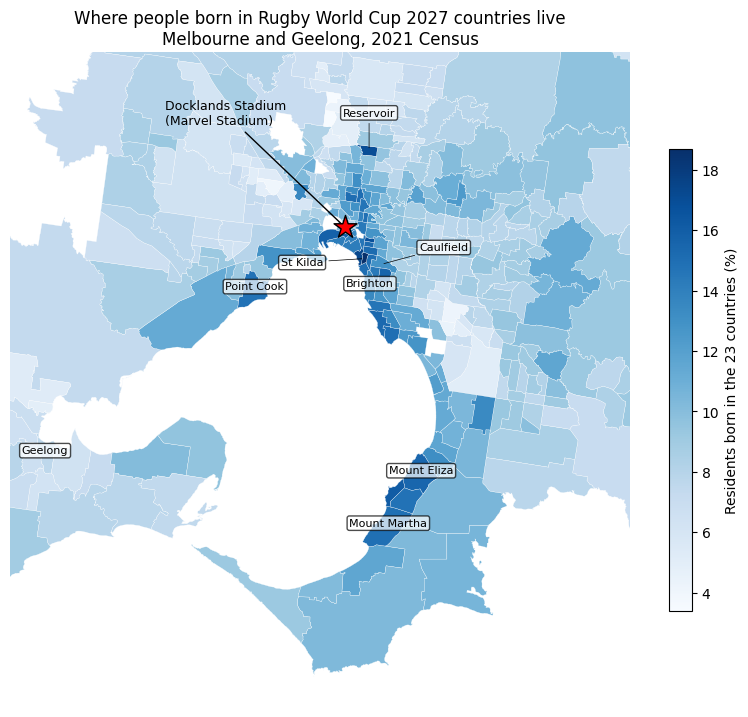

In [103]:
import matplotlib.pyplot as plt

label_areas = {
    'St Kilda - Central': ('St Kilda', (-45, -5)),
    'Brighton (Vic.)': ('Brighton', (0, 0)),
    'Caulfield - North': ('Caulfield', (45, 10)),
    'Mount Eliza': ('Mount Eliza', (0, 0)),
    'Mount Martha': ('Mount Martha', (0, 0)),
    'Point Cook - East': ('Point Cook', (0, 0)),
    'Geelong': ('Geelong', (0, 0)),
    'Reservoir - North West': ('Reservoir', (0, 25)),
}

fig, ax = plt.subplots(figsize=(10, 10))
map_df.plot(column='world_cup_share', cmap='Blues', linewidth=0.2, edgecolor='white',
            legend=True, ax=ax,
            legend_kwds={'label': 'Residents born in the 23 countries (%)', 'shrink': 0.6})
ax.set_xlim(144.3, 145.5)
ax.set_ylim(-38.55, -37.55)

stadium_lon, stadium_lat = 144.9475, -37.8165
ax.scatter(stadium_lon, stadium_lat, marker='*', s=300, color='red', edgecolor='black', zorder=5)
ax.annotate('Docklands Stadium\n(Marvel Stadium)', xy=(stadium_lon, stadium_lat),
            xytext=(144.60, -37.66), fontsize=9,
            arrowprops=dict(arrowstyle='-', color='black'))

for sa2, (label, offset) in label_areas.items():
    points = map_df.loc[map_df['sa2_name'] == sa2, 'geometry'].representative_point()
    if len(points) == 0:
        print('Not found:', sa2)
        continue
    p = points.iloc[0]
    ax.annotate(label, xy=(p.x, p.y), xytext=offset, textcoords='offset points',
                fontsize=8, ha='center',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7),
                arrowprops=dict(arrowstyle='-', color='black', lw=0.5) if offset != (0, 0) else None)

ax.set_title('Where people born in Rugby World Cup 2027 countries live\nMelbourne and Geelong, 2021 Census')
ax.set_axis_off()
plt.savefig('a03_main_map.png', dpi=200, bbox_inches='tight')
plt.show()

**Result:**
- **East side of the bay:** the darkest areas run from St Kilda through the bayside suburbs to Mount Eliza and Mount Martha.
- **West side of the bay:** a lighter band runs towards Point Cook.
- **North:** one dark area, Reservoir – North West (checked below).
- **Lightest:** most of the north-west and parts of the south-east. Geelong is light to medium.
- The map shows the same pattern as the top 10 tables, across all 377 areas.

In [104]:
map_df.sort_values('world_cup_share', ascending=False).head(5)[['sa2_name', 
                                                                'world_cup_share', 
                                                                'top_country', 
                                                                'top_country_pct']]

,sa2_name,world_cup_share,top_country,top_country_pct
58,St Kilda - Central,18.7,England,28.0
59,St Kilda - West,17.3,England,30.6
138,Reservoir - North West,17.0,Italy,80.6
63,South Yarra - North,16.8,England,26.4
376,Mornington - West,16.1,England,58.6


**Result:** The five areas with the highest share are the darkest on the map.

* St Kilda – Central, St Kilda – West and South Yarra – North: England is the top country but only 26–31% of World Cup-born residents, so several countries contribute.

* Mornington – West: England is the top country, with 58.6% of World Cup-born residents, similar to Mount Eliza and Mount Martha nearby.

* Reservoir – North West: 80.6% of World Cup-born residents were born in Italy, so this area's share depends almost entirely on one country. Like England, Italy plays its pool matches outside Melbourne.


### Where each country's community lives
To target promotion for individual matches, I list each country's total and the area where most of its residents live.

In [105]:
rows = []
for c in country_cols_all:
    top = df_merged.loc[df_merged[c].idxmax()]
    rows.append({'country': c.replace('P_', '').replace('_Tot', ''),
                 'total_people': df_merged[c].sum(),
                 'top_area': top['sa2_name'],
                 'top_area_people': top[c]})

country_top = pd.DataFrame(rows).sort_values('total_people', ascending=False)
country_top

,country,total_people,top_area,top_area_people
2,England,143701,Mount Martha,1746
9,New_Zealand,86451,Tarneit - Central,979
7,Italy,59860,Reservoir - North West,1341
12,South_Africa,28215,Caulfield - South,1033
5,Hong_Kong_SAR_Ch,24725,Doncaster,892
13,USA,21297,Caulfield - North,382
11,Scotland,21268,Langwarrin,253
6,Ireland,15630,St Kilda - Central,314
3,Fiji,11625,Lynbrook - Lyndhurst,190
0,Canada,9000,Prahran - Windsor,102


**Result:** Among the teams that play in Melbourne, New Zealand (86,451), Hong Kong China (24,725), the USA (21,297), Scotland (21,268) and Ireland (15,630) have the largest communities. Argentina, Wales, Spain, Uruguay and Tonga have fewer than 4,500 each, and no single area has more than 57 of them.

## Step 8: Findings, recommendations and limitations

### Findings
1. **About 1 in 11 residents.** Across the 377 areas, 481,388 of 5,245,328 residents (9.2%) were born in one of the 23 countries.
2. **One clear band.** The highest shares run along the east side of Port Phillip Bay, from St Kilda through the bayside suburbs to Mount Eliza and Mount Martha on the Mornington Peninsula.
3. **Demand is spread, not concentrated in one suburb.** The top 10 areas by number range only from 2,724 to 3,071 people.
4. **England is the main country in most top areas**, and in Mount Eliza (59.7%) and Mount Martha (58.9%) more than half of World Cup-born residents were born in England. Other areas are led by other countries: Caulfield (South Africa), Point Cook – East (New Zealand) and Reservoir – North West (Italy).
5. **Geelong is not a priority.** None of its areas appear in either top 10.

### Where promotion could start
Based on where potential demand is concentrated:
1. **St Kilda to Brighton first.** High shares and the closest part of the band to Docklands Stadium.

2. **The Mornington Peninsula second.** High shares, mostly England-born, but much further from the stadium, so promotion would need travel information.

4. **Community-specific promotion for the Melbourne matches.** For each team that plays in Melbourne, the area with the most residents born in that country is: New Zealand, Tarneit – Central, and Hong Kong China, Doncaster (New Zealand v Hong Kong China, 15 October); Ireland, St Kilda – Central (Ireland v Uruguay, 17 October); Scotland and Wales, Langwarrin (Scotland v Uruguay, 3 October; Wales v Tonga, 8 October); France and the USA, Caulfield – North (France v USA, 2 October). Argentina, Spain, Uruguay and Tonga-born residents are fewer (1,406 to 4,320 each) and spread out, with no more than 55 in any one area, so promotion for these communities would need to cover the whole city rather than one area.

England, South Africa and Italy play their pool matches outside Melbourne, so for these groups demand in Melbourne is more likely to be for the Round of 16 matches, neutral matches or travel to other cities.

### Limitations
- **Country of birth is a proxy.** It assumes people born in a country are more likely to want to watch its team. It misses Australian-born fans and the children of migrants.
- **2021 Census, during COVID-19.** The Census was held on 10 August 2021, while the border was closed and Melbourne was in lockdown, so temporary residents such as international students may be undercounted.
- **Country of birth is not nationality.** It counts people born in a country, whatever their citizenship.
- **Areas were selected by SA4 region.** I kept the SA2 areas whose SA4 region (the first three digits of the code) is Greater Melbourne or Geelong. These regions also include nearby towns and rural areas, not only the cities.
- **Two data sources.** 16 countries come from Census table G09 and 7 (Argentina, Georgia, Portugal, Romania, Spain, Tonga, Uruguay) from ABS Census TableBuilder, matched by area name. The ABS randomly adjusts small counts in both, so totals may differ slightly from other ABS tables.
- **No ticket sales data.** This shows potential demand, not actual buyers.

### Next steps
- Update with the 2026 Census once it is released (expected from 2027).
- Look at each Melbourne match separately (e.g. Welsh-born residents for Wales v Tonga).
- Compare the results with actual ticket sales by postcode, if the organisers can share them. This would test whether country of birth is a good guide to demand.
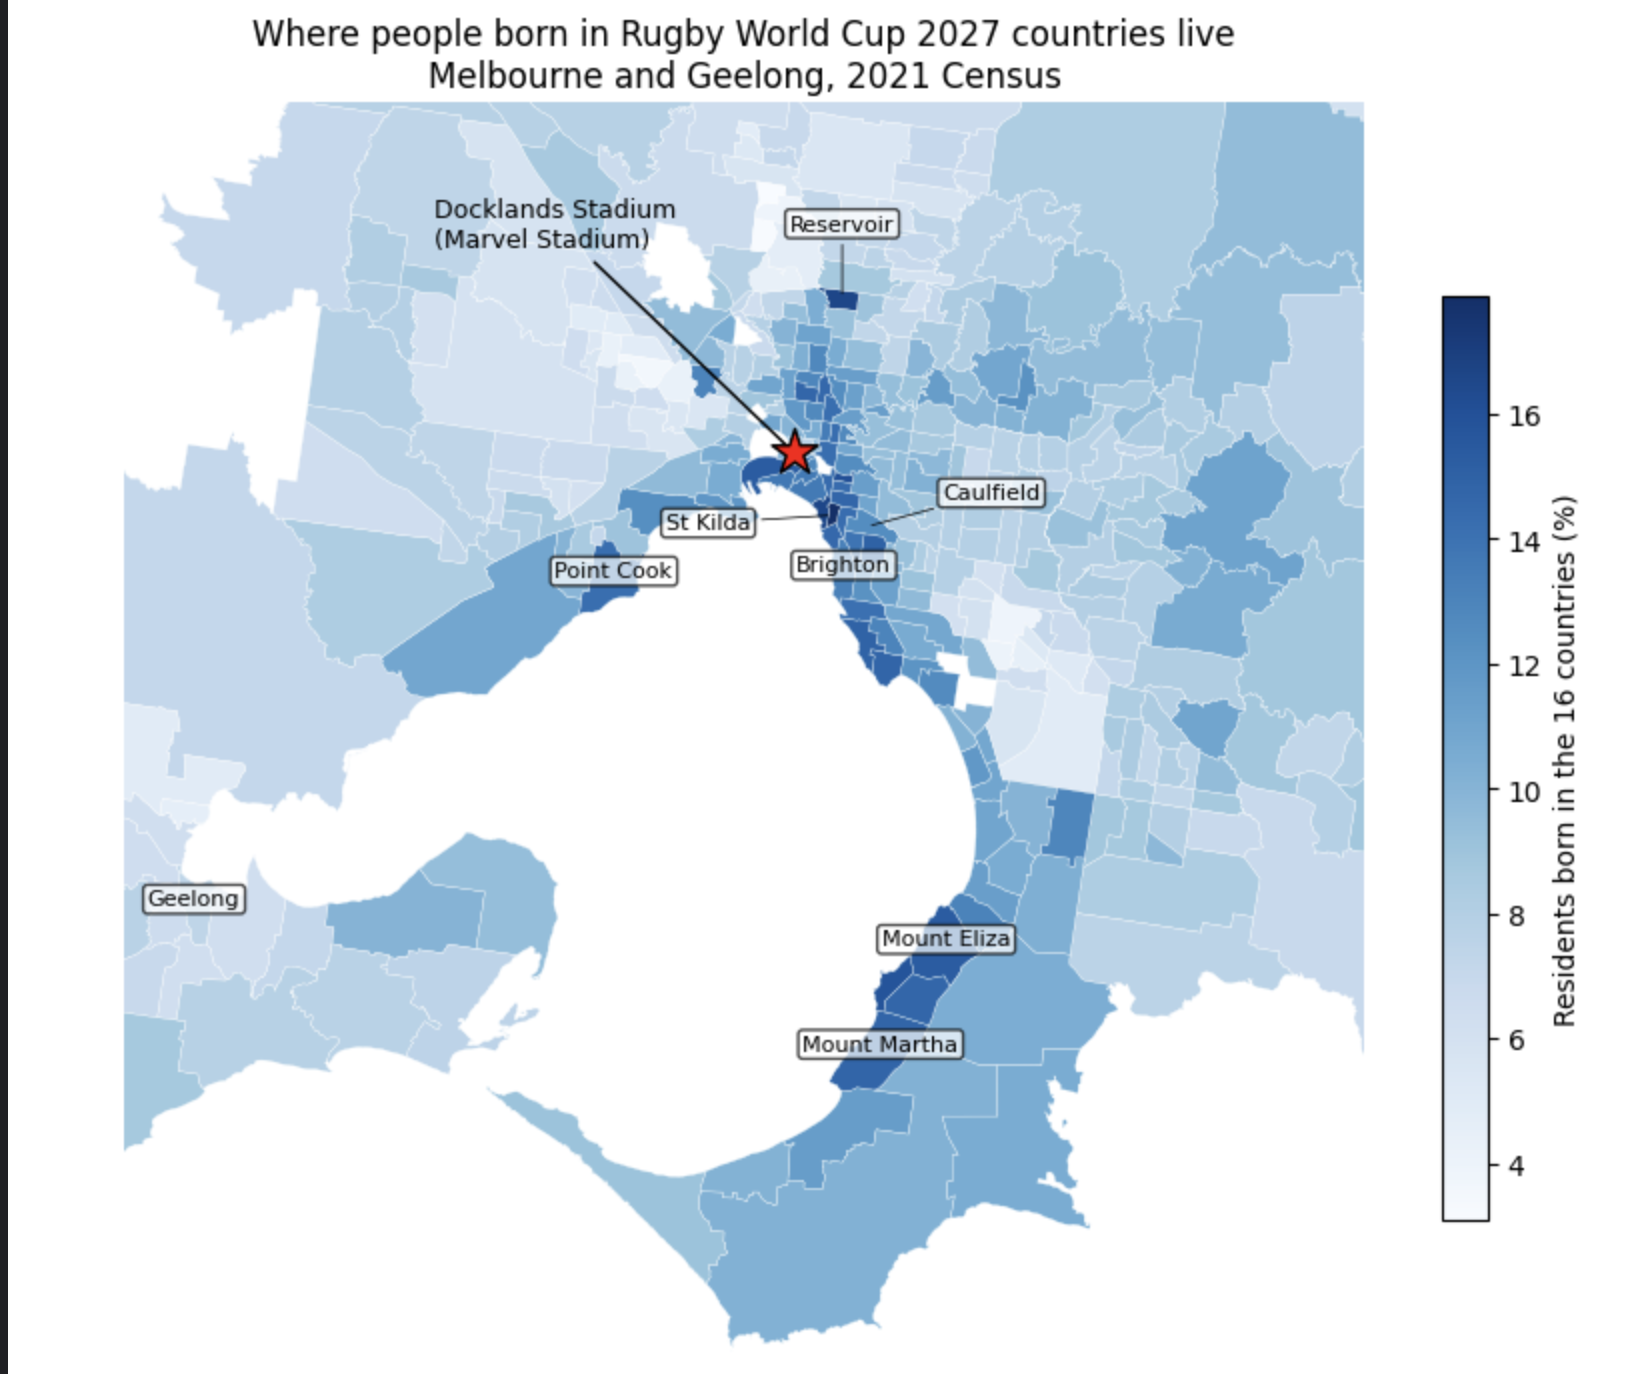

## Step 9: Save the results
I save one row per area, sorted by number, so the results can be used without running the notebook.

In [106]:
out_cols = ['SA2_CODE_2021', 'sa2_name', 'city', 'P_Tot_Tot', 'world_cup_born',
            'world_cup_share', 'top_country', 'top_country_pct']
results = df_merged[out_cols].sort_values('world_cup_born', ascending=False)
results.to_csv('a03_world_cup_born_by_sa2.csv', index=False)

print(results.shape)
results.head(3)

(377, 8)


,SA2_CODE_2021,sa2_name,city,P_Tot_Tot,world_cup_born,world_cup_share,top_country,top_country_pct
99,208011169,Brighton (Vic.),Melbourne,22758,3071,13.5,England,40.2
371,214021382,Mount Martha,Melbourne,19846,2962,14.9,England,58.9
104,208021174,Bentleigh - McKinnon,Melbourne,24896,2917,11.7,England,29.0


**Result:** `a03_world_cup_born_by_sa2.csv` has 377 rows (one per area) and 8 columns, sorted by the number of World Cup-born residents. It is saved in the notebook's Output folder.